# 3. Machine Learning Implementation — Whole-Leaf Features

This notebook compares five classifiers using 17 numerical features extracted from the whole-leaf region.

**Final model: Support Vector Machine (SVM).** The SVM is selected because it achieved the highest Macro F1 on the current test split. The notebook also evaluates Decision Tree, Random Forest, Naive Bayes, and a Dummy Baseline.

## 3.1 Import Libraries and Set Project Paths

In [1]:
from pathlib import Path
import shutil

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

DATA_PATH = Path("data") / "citrus_features_8_classes.csv"

MODEL_DIR = Path("model_files")
RESULTS_DIR = Path("model_results")

MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Feature dataset:", DATA_PATH.resolve())
print("Model folder:", MODEL_DIR.resolve())
print("Results folder:", RESULTS_DIR.resolve())

Feature dataset: C:\Users\Shakir Ali\Downloads\Orange_Leaf_ML_Project\data\citrus_features_8_classes.csv
Model folder: C:\Users\Shakir Ali\Downloads\Orange_Leaf_ML_Project\model_files
Results folder: C:\Users\Shakir Ali\Downloads\Orange_Leaf_ML_Project\model_results


## 3.2 Load the Feature Dataset

In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Number of classes:", df["class"].nunique())
print("\nClass counts:")
print(df["class"].value_counts())

Dataset shape: (623, 19)
Number of classes: 8

Class counts:
class
Fe             100
Greasy_spot    100
Healthy        100
Mg             100
Zn             100
N               50
HLB             43
Mn              30
Name: count, dtype: int64


## 3.3 Select Model Features

The image filename is used only to locate the original image and its matching leaf-region file. It is **not** used as a model input.

The classifiers receive only the 17 numerical features.

In [3]:
FEATURE_COLUMNS = [
    "mean_R", "mean_G", "mean_B",
    "std_R", "std_G", "std_B",
    "mean_H", "mean_S", "mean_V",
    "std_H", "std_S", "std_V",
    "green_ratio", "yellow_ratio", "dark_ratio",
    "gray_std", "edge_density"
]

X = df[FEATURE_COLUMNS]
y = df["class"]

print("Samples:", len(df))
print("Features:", len(FEATURE_COLUMNS))

Samples: 623
Features: 17


## 3.4 Train/Test Split

The dataset is divided into:

- 80% training data
- 20% testing data
- stratified class distribution
- `random_state=42`

The test portion is kept separate from model fitting.

In [4]:
train_indices, test_indices = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

train_df = df.iloc[train_indices].copy()
test_df = df.iloc[test_indices].copy()

X_train = train_df[FEATURE_COLUMNS]
X_test = test_df[FEATURE_COLUMNS]

y_train = train_df["class"]
y_test = test_df["class"]

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

Training samples: 498
Testing samples: 125


## 3.5 Export the Test Images for the Model Demonstration

This cell copies **only the test images** and their matching whole-leaf region files into a separate folder. It uses the same test split as the model evaluation above.

Place the original dataset beside this project folder using this structure:

- `CitrusUAT_Selected_Dataset/Images`
- `CitrusUAT_Selected_Dataset/Masks`

The source dataset uses filenames such as `Fe_001.jpg` and `Fe_001_mask.png`. In the demonstration folder, the region file is renamed to `Fe_001_region.png` so generated filenames do not all carry the word “mask”.

If the image dataset is not present, this cell skips the export. The model training can still run from the included feature CSV.

In [5]:
DATASET_ROOT = Path("CitrusUAT_Selected_Dataset")
SOURCE_IMAGE_DIR = DATASET_ROOT / "Images"
SOURCE_REGION_DIR = DATASET_ROOT / "Masks"

DEMO_DIR = Path("model_testing_data")
DEMO_IMAGE_DIR = DEMO_DIR / "Images"
DEMO_REGION_DIR = DEMO_DIR / "Leaf_Regions"

if SOURCE_IMAGE_DIR.exists() and SOURCE_REGION_DIR.exists():

    DEMO_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    DEMO_REGION_DIR.mkdir(parents=True, exist_ok=True)

    manifest_rows = []

    def find_source_region(image_name):
        image_stem = Path(image_name).stem
        extensions = [".png", ".jpg", ".jpeg", ".PNG", ".JPG", ".JPEG"]

        for extension in extensions:
            candidate = SOURCE_REGION_DIR / f"{image_stem}_mask{extension}"
            if candidate.exists():
                return candidate

        return None

    for _, row in test_df.iterrows():

        image_name = str(row["image_name"])
        actual_class = str(row["class"])

        source_image = SOURCE_IMAGE_DIR / image_name
        source_region = find_source_region(image_name)

        if not source_image.exists():
            raise FileNotFoundError(f"Test image not found: {source_image}")

        if source_region is None:
            raise FileNotFoundError(
                f"Matching leaf-region file not found for: {image_name}"
            )

        region_name = (
            Path(image_name).stem
            + "_region"
            + source_region.suffix.lower()
        )

        shutil.copy2(
            source_image,
            DEMO_IMAGE_DIR / image_name
        )

        shutil.copy2(
            source_region,
            DEMO_REGION_DIR / region_name
        )

        manifest_rows.append({
            "image_name": image_name,
            "region_name": region_name,
            "actual_class": actual_class
        })

    test_manifest = pd.DataFrame(manifest_rows)
    test_manifest.to_csv(
        DEMO_DIR / "test_manifest.csv",
        index=False
    )

    print("Exported test images:", len(test_manifest))
    print("Demonstration folder:", DEMO_DIR.resolve())

else:
    print(
        "Dataset image folders were not found. "
        "Add CitrusUAT_Selected_Dataset beside this project and rerun this cell to export the test images."
    )

Exported test images: 125
Demonstration folder: C:\Users\Shakir Ali\Downloads\Orange_Leaf_ML_Project\model_testing_data


## 3.6 Define the Models

In [6]:
models = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            SVC(
                kernel="rbf",
                class_weight="balanced"
            )
        )
    ]),

    "Naive Bayes": GaussianNB()
}

print("Models ready.")

Models ready.


## 3.7 Cross-Validation

Five-fold stratified cross-validation is performed on the training data only.

Macro F1 is used so that performance across all eight classes is considered, including classes with fewer images.

In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_rows = []

for model_name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    cv_rows.append({
        "Model": model_name,
        "Mean Macro F1": scores.mean(),
        "Std Macro F1": scores.std()
    })

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values(
        "Mean Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(cv_results.round(4))

,Model,Mean Macro F1,Std Macro F1
0,Random Forest,0.8976,0.0247
1,SVM,0.8805,0.0209
2,Naive Bayes,0.8383,0.0328
3,Decision Tree,0.8111,0.0415
4,Dummy Baseline,0.0346,0.0001


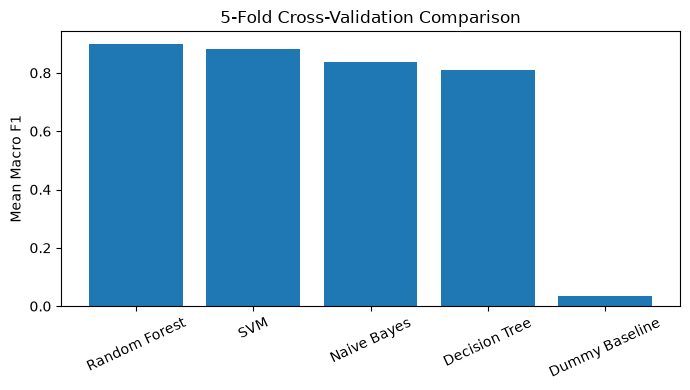

In [8]:
plt.figure(figsize=(7, 4))

plt.bar(
    cv_results["Model"],
    cv_results["Mean Macro F1"]
)

plt.title("5-Fold Cross-Validation Comparison")
plt.ylabel("Mean Macro F1")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

## 3.8 Train All Models

In [9]:
trained_models = {}

for model_name, model in models.items():

    model.fit(
        X_train,
        y_train
    )

    trained_models[model_name] = model

print("All models trained.")

All models trained.


## 3.9 Final Test Evaluation

In [10]:
predictions = {}
result_rows = []

for model_name, model in trained_models.items():

    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    result_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

test_results = (
    pd.DataFrame(result_rows)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(test_results.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SVM,0.856,0.8619,0.8597,0.8556
1,Naive Bayes,0.816,0.8494,0.8285,0.8333
2,Random Forest,0.840,0.8436,0.8188,0.8274
3,Decision Tree,0.760,0.7704,0.7361,0.7443
4,Dummy Baseline,0.160,0.0200,0.1250,0.0345


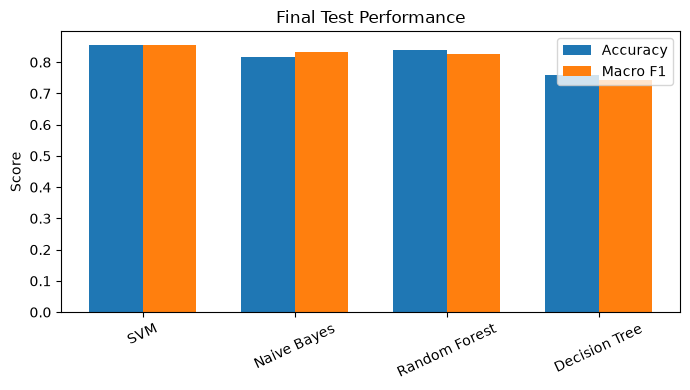

In [11]:
plot_results = test_results[
    test_results["Model"] != "Dummy Baseline"
].copy()

x = np.arange(len(plot_results))
width = 0.35

plt.figure(figsize=(7, 4))

plt.bar(
    x - width / 2,
    plot_results["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    plot_results["Macro F1"],
    width,
    label="Macro F1"
)

plt.xticks(
    x,
    plot_results["Model"],
    rotation=25
)

plt.ylabel("Score")
plt.title("Final Test Performance")
plt.legend()

plt.tight_layout()
plt.show()

## 3.10 Final Model Selection — SVM

The final model for this project is **Support Vector Machine (SVM)**.

On the current 20% test split, SVM achieved the highest Macro F1 among the five evaluated models. Random Forest had a higher mean cross-validation Macro F1, but SVM performed better on this test split. The final selection in this project is therefore based on the test Macro F1 comparison.

The SVM pipeline includes `StandardScaler` because SVM is sensitive to the scale of numerical features.

In [12]:
FINAL_MODEL_NAME = "SVM"
final_model = trained_models[FINAL_MODEL_NAME]

svm_predictions = predictions[FINAL_MODEL_NAME]

svm_test_row = test_results[
    test_results["Model"] == FINAL_MODEL_NAME
].iloc[0]

print("Selected final model:", FINAL_MODEL_NAME)
print("Test accuracy:", round(svm_test_row["Accuracy"], 4))
print("Test Macro F1:", round(svm_test_row["Macro F1"], 4))

Selected final model: SVM
Test accuracy: 0.856
Test Macro F1: 0.8556


## 3.11 SVM Class-Level Performance

In [13]:
svm_report = classification_report(
    y_test,
    svm_predictions,
    output_dict=True,
    zero_division=0
)

svm_report_df = pd.DataFrame(svm_report).T

CLASS_ORDER = [
    "Healthy",
    "Fe",
    "Mg",
    "Mn",
    "N",
    "Zn",
    "HLB",
    "Greasy_spot"
]

class_rows = [
    class_name
    for class_name in CLASS_ORDER
    if class_name in svm_report_df.index
]

display(
    svm_report_df.loc[
        class_rows,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

,precision,recall,f1-score,support
Healthy,0.9000,0.9000,0.9000,20.0
Fe,0.9474,0.9000,0.9231,20.0
Mg,0.6522,0.7500,0.6977,20.0
Mn,0.7500,1.0000,0.8571,6.0
N,0.8000,0.8000,0.8000,10.0
Zn,0.9048,0.9500,0.9268,20.0
HLB,1.0000,0.7778,0.8750,9.0
Greasy_spot,0.9412,0.8000,0.8649,20.0


## 3.12 SVM Confusion Matrix — Final Model

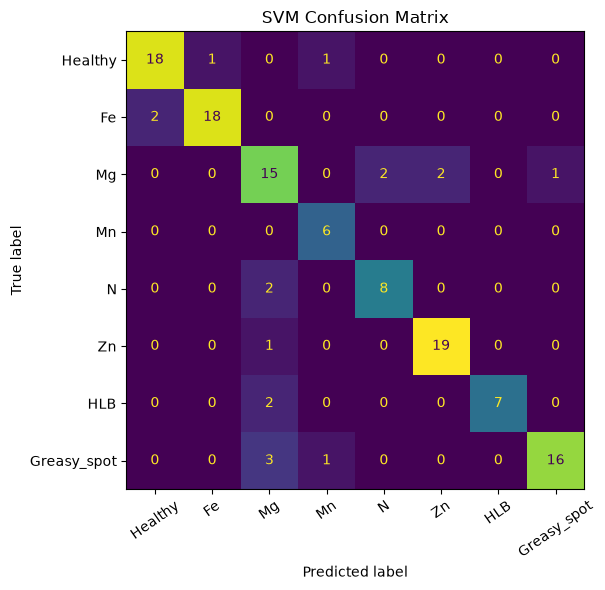

In [14]:
cm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=CLASS_ORDER
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_ORDER
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    colorbar=False,
    xticks_rotation=35,
    values_format="d"
)

plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "svm_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## 3.13 Save Models and Results

In [15]:
model_filenames = {
    "Dummy Baseline": "dummy_baseline.pkl",
    "Decision Tree": "decision_tree_citrus_model.pkl",
    "Random Forest": "random_forest_citrus_model.pkl",
    "SVM": "svm_citrus_model.pkl",
    "Naive Bayes": "naive_bayes_citrus_model.pkl"
}

for model_name, filename in model_filenames.items():

    joblib.dump(
        trained_models[model_name],
        MODEL_DIR / filename
    )

# Save the selected final model explicitly for the Streamlit app.
joblib.dump(
    final_model,
    MODEL_DIR / "svm_citrus_model.pkl"
)

joblib.dump(
    FEATURE_COLUMNS,
    MODEL_DIR / "feature_columns.pkl"
)

cv_results.to_csv(
    RESULTS_DIR / "model_cross_validation_results.csv",
    index=False
)

test_results.to_csv(
    RESULTS_DIR / "model_test_results.csv",
    index=False
)

svm_report_df.to_csv(
    RESULTS_DIR / "svm_classification_report.csv"
)

pd.DataFrame(
    cm,
    index=CLASS_ORDER,
    columns=CLASS_ORDER
).to_csv(
    RESULTS_DIR / "svm_confusion_matrix.csv"
)

test_df[
    ["image_name", "class"]
].rename(
    columns={"class": "actual_class"}
).to_csv(
    RESULTS_DIR / "test_image_names.csv",
    index=False
)

print("Final model saved:", (MODEL_DIR / "svm_citrus_model.pkl").resolve())
print("Other comparison models and results saved.")

Final model saved: C:\Users\Shakir Ali\Downloads\Orange_Leaf_ML_Project\model_files\svm_citrus_model.pkl
Other comparison models and results saved.


# Final ML Conclusion

The final selected model is **SVM**.

It achieved the highest Macro F1 on the current held-out test split among the evaluated models. Its confusion matrix and class-level report are shown above. The Random Forest remains in the comparison because it is one of the required candidate models, but it is not the final model used by the Streamlit application.

The test split was used while comparing candidate models. It was held out from model fitting, but it was not an untouched external test set throughout the full model-selection process.